In [1]:
!pip install requests beautifulsoup4 pandas matplotlib seaborn

In [2]:

import requests
from bs4 import BeautifulSoup

url = "https://www.bikewale.com/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

try:
    response = requests.get(
        url,
        headers=headers,
        timeout=20
    )

    print("Status Code:", response.status_code)
    print("Page Size:", len(response.text))

    soup = BeautifulSoup(response.text, "html.parser")

    if soup.title:
        print("Website Title:", soup.title.get_text(strip=True))
    else:
        print("Website title not found")

except requests.RequestException as e:
    print("Error:", e)


Status Code: 200
Page Size: 627318
Website Title: New Bikes, New Scooters, Electric Bikes - BikeWale


In [3]:

brand_url = "https://www.bikewale.com/tvs-bikes/"

response = requests.get(
    brand_url,
    headers=headers,
    timeout=20
)

print("Status Code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print("Page Title:", soup.title.get_text(strip=True) if soup.title else "Not found")

# Check bike-related text in the HTML
page_text = soup.get_text(" ", strip=True)

for keyword in ["Apache", "Raider", "Ronin", "Price", "Mileage"]:
    print(keyword, ":", keyword.lower() in page_text.lower())

# Display some links found on the page
for link in soup.select("a[href]")[:20]:
    text = link.get_text(" ", strip=True)
    href = link.get("href", "")
    if text:
        print(text[:60], "->", href)


Status Code: 200
Page Title: TVS Bikes Price in India - New TVS Models 2026, Images & Specs - BikeWale
Apache : True
Raider : True
Ronin : True
Price : True
Mileage : True
TVS Apache RTR 160 -> /tvs-bikes/apache-160/
TVS Ronin -> /tvs-bikes/ronin/
TVS Raider 125 -> /tvs-bikes/raider-125/
All-New Pulsar 125 - Loaded with TFT Intelligence Bajaj Puls -> /bajaj-bikes/pulsar-125/
TVS iQube -> /tvs-bikes/iqube/
TVS Jupiter -> /tvs-bikes/jupiter/
TVS Jupiter 125 -> /tvs-bikes/jupiter-125/
TVS Ntorq 125 -> /tvs-bikes/ntorq-125/
TVS Apache RTR 160 4V -> /tvs-bikes/apache-rtr-160-4v/
TVS Apache RR 310 -> /tvs-bikes/apache-rr-310/
TVS Ntorq 150 -> /tvs-bikes/ntorq-150/
TVS Orbiter -> /tvs-bikes/orbiter/
TVS Radeon -> /tvs-bikes/radeon/
TVS XL 100 Heavy Duty -> /tvs-bikes/xl-100-heavy-duty/
TVS Apache RTR 310 -> /tvs-bikes/apache-rtr-310/
TVS Apache RTR 200 4V -> /tvs-bikes/apache-200/
TVS Apache RTX -> /tvs-bikes/apache-rtx/
TVS Sport -> /tvs-bikes/sport/
TVS Apache RTR 180 -> /tvs-bikes/apache-1

In [4]:

# Inspect the first few bike links and their surrounding text

bike_links = soup.select('a[href*="/tvs-bikes/"]')

count = 0

for link in bike_links:
    bike_name = link.get_text(" ", strip=True)

    if bike_name:
        print("Bike Name:", bike_name)
        print("Link:", link.get("href"))
        print("Nearby Details:", link.parent.get_text(" ", strip=True)[:300])
        print("-" * 60)

        count += 1

    if count == 5:
        break


Bike Name: TVS Apache RTR 160
Link: /tvs-bikes/apache-160/
Nearby Details: 4.5 /5 3364 Ratings TVS Apache RTR 160 159.7 cc | 45 kmpl | 15.82 bhp | 137 kg ₹ 1,10,524 Avg. Ex-Showroom price Check On-Road Price
------------------------------------------------------------
Bike Name: TVS Ronin
Link: /tvs-bikes/ronin/
Nearby Details: 4.6 /5 1191 Ratings TVS Ronin 225.9 cc | 41 kmpl | 20.1 bhp | 159 kg ₹ 1,30,809 Avg. Ex-Showroom price Check On-Road Price
------------------------------------------------------------
Bike Name: TVS Raider 125
Link: /tvs-bikes/raider-125/
Nearby Details: 4.4 /5 2982 Ratings TVS Raider 125 124.8 cc | 56 kmpl | 11.2 bhp | 123 kg ₹ 86,937 Avg. Ex-Showroom price Check On-Road Price
------------------------------------------------------------
Bike Name: TVS iQube
Link: /tvs-bikes/iqube/
Nearby Details: 3.6 /5 925 Ratings TVS iQube 68 kmph | 114 km | 115 kg | 3.68 kW ₹ 1,19,444 Avg. Ex-Showroom price Check On-Road Price
------------------------------------------------

In [5]:
import re
import pandas as pd
from urllib.parse import urljoin
from bs4 import BeautifulSoup
import requests

brand_url = "https://www.bikewale.com/tvs-bikes/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    brand_url,
    headers=headers,
    timeout=20
)

soup = BeautifulSoup(response.text, "html.parser")

bike_data = []
seen_urls = set()

for link in soup.select('a[href*="/tvs-bikes/"]'):

    bike_name = link.get_text(" ", strip=True)
    bike_url = urljoin(brand_url, link.get("href", ""))
    details = link.parent.get_text(" ", strip=True)

    price_match = re.search(r'₹\s*([\d,]+)', details)

    if not bike_name or not price_match:
        continue

    if bike_url in seen_urls:
        continue

    seen_urls.add(bike_url)

    engine = re.search(r'([\d.]+)\s*cc', details, re.I)
    mileage = re.search(r'([\d.]+)\s*kmpl', details, re.I)
    power = re.search(r'([\d.]+)\s*bhp', details, re.I)
    weight = re.search(r'([\d.]+)\s*kg', details, re.I)
    rating = re.search(r'(\d+(?:\.\d+)?)\s*/\s*5', details)
    ratings_count = re.search(r'([\d,]+)\s+Ratings?', details, re.I)

    bike_data.append({
        "Bike_Name": bike_name,
        "Brand": "TVS",
        "Price_Raw": price_match.group(0),
        "Engine_Capacity_Raw": engine.group(0) if engine else None,
        "Mileage_Raw": mileage.group(0) if mileage else None,
        "Power_Raw": power.group(0) if power else None,
        "Weight_Raw": weight.group(0) if weight else None,
        "User_Rating": rating.group(1) if rating else None,
        "Rating_Count": ratings_count.group(1) if ratings_count else None,
        "Product_URL": bike_url,
        "Raw_Details": details
    })

df_tvs = pd.DataFrame(bike_data)

df_tvs.to_csv("tvs_bikes_raw.csv", index=False)

print("Total records collected:", len(df_tvs))
display(df_tvs.head(10))

print("CSV file saved successfully!")

Total records collected: 29


,Bike_Name,Brand,Price_Raw,Engine_Capacity_Raw,Mileage_Raw,Power_Raw,Weight_Raw,User_Rating,Rating_Count,Product_URL,Raw_Details
0,TVS Apache RTR 160,TVS,"₹ 1,10,524",159.7 cc,45 kmpl,15.82 bhp,137 kg,4.5,3364,https://www.bikewale.com/tvs-bikes/apache-160/,4.5 /5 3364 Ratings TVS Apache RTR 160 159.7 c...
1,TVS Ronin,TVS,"₹ 1,30,809",225.9 cc,41 kmpl,20.1 bhp,159 kg,4.6,1191,https://www.bikewale.com/tvs-bikes/ronin/,4.6 /5 1191 Ratings TVS Ronin 225.9 cc | 41 km...
2,TVS Raider 125,TVS,"₹ 86,937",124.8 cc,56 kmpl,11.2 bhp,123 kg,4.4,2982,https://www.bikewale.com/tvs-bikes/raider-125/,4.4 /5 2982 Ratings TVS Raider 125 124.8 cc | ...
3,TVS iQube,TVS,"₹ 1,19,444",None,None,None,115 kg,3.6,925,https://www.bikewale.com/tvs-bikes/iqube/,3.6 /5 925 Ratings TVS iQube 68 kmph | 114 km ...
4,TVS Jupiter,TVS,"₹ 77,371",113.3 cc,49 kmpl,7.91 bhp,105 kg,4.5,1199,https://www.bikewale.com/tvs-bikes/jupiter/,4.5 /5 1199 Ratings TVS Jupiter 113.3 cc | 49 ...
5,TVS Jupiter 125,TVS,"₹ 87,860",124.8 cc,48 kmpl,8.04 bhp,108 kg,4.1,968,https://www.bikewale.com/tvs-bikes/jupiter-125/,4.1 /5 968 Ratings TVS Jupiter 125 124.8 cc | ...
6,TVS Ntorq 125,TVS,"₹ 91,056",124.8 cc,43 kmpl,9.25 bhp,111 kg,4.4,2315,https://www.bikewale.com/tvs-bikes/ntorq-125/,4.4 /5 2315 Ratings TVS Ntorq 125 124.8 cc | 4...
7,TVS Apache RTR 160 4V,TVS,"₹ 1,16,480",159.7 cc,45 kmpl,17.31 bhp,144 kg,4.5,2337,https://www.bikewale.com/tvs-bikes/apache-rtr-...,4.5 /5 2337 Ratings TVS Apache RTR 160 4V 159....
8,TVS Apache RR 310,TVS,"₹ 2,66,179",312.2 cc,32 kmpl,37.54 bhp,174 kg,4.7,217,https://www.bikewale.com/tvs-bikes/apache-rr-310/,4.7 /5 217 Ratings TVS Apache RR 310 312.2 cc ...
9,TVS Ntorq 150,TVS,"₹ 1,12,931",149.7 cc,40.5 kmpl,13 bhp,115 kg,4.5,150,https://www.bikewale.com/tvs-bikes/ntorq-150/,4.5 /5 150 Ratings TVS Ntorq 150 149.7 cc | 40...


CSV file saved successfully!


In [6]:
# Check the collected data
print("Total Rows:", len(df_tvs))
print("Total Columns:", len(df_tvs.columns))

print("\nColumn Names:")
print(df_tvs.columns.tolist())

print("\nMissing Values:")
print(df_tvs.isnull().sum())

# Download the raw dataset
from google.colab import files
files.download("tvs_bikes_raw.csv")

Total Rows: 29
Total Columns: 11

Column Names:
['Bike_Name', 'Brand', 'Price_Raw', 'Engine_Capacity_Raw', 'Mileage_Raw', 'Power_Raw', 'Weight_Raw', 'User_Rating', 'Rating_Count', 'Product_URL', 'Raw_Details']

Missing Values:
Bike_Name               0
Brand                   0
Price_Raw               0
Engine_Capacity_Raw    10
Mileage_Raw            10
Power_Raw              10
Weight_Raw              8
User_Rating             7
Rating_Count            7
Product_URL             0
Raw_Details             0
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import pandas as pd
import re

# Create a copy of the collected data
df = df_tvs.copy()

# Remove duplicate records
df = df.drop_duplicates(subset=["Bike_Name", "Product_URL"])

# Clean Price
df["Price"] = pd.to_numeric(
    df["Price_Raw"].str.replace(r"[₹,\s]", "", regex=True),
    errors="coerce"
)

# Extract Engine Capacity
df["Engine_Capacity_cc"] = pd.to_numeric(
    df["Engine_Capacity_Raw"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

# Extract Mileage
df["Mileage_kmpl"] = pd.to_numeric(
    df["Mileage_Raw"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

# Extract Power
df["Power_bhp"] = pd.to_numeric(
    df["Power_Raw"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

# Extract Weight
df["Weight_kg"] = pd.to_numeric(
    df["Weight_Raw"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

# Convert Ratings to numbers
df["User_Rating"] = pd.to_numeric(
    df["User_Rating"], errors="coerce"
)

df["Rating_Count"] = pd.to_numeric(
    df["Rating_Count"].str.replace(",", "", regex=False),
    errors="coerce"
)

# Remove unnecessary raw columns
df_cleaned = df.drop(columns=[
    "Price_Raw",
    "Engine_Capacity_Raw",
    "Mileage_Raw",
    "Power_Raw",
    "Weight_Raw",
    "Raw_Details"
])

print("Total Rows:", len(df_cleaned))
print("Total Columns:", len(df_cleaned.columns))

print("\nMissing Values:")
print(df_cleaned.isnull().sum())

display(df_cleaned.head(10))

Total Rows: 29
Total Columns: 10

Missing Values:
Bike_Name              0
Brand                  0
User_Rating            7
Rating_Count           7
Product_URL            0
Price                  0
Engine_Capacity_cc    10
Mileage_kmpl          10
Power_bhp             10
Weight_kg              8
dtype: int64


,Bike_Name,Brand,User_Rating,Rating_Count,Product_URL,Price,Engine_Capacity_cc,Mileage_kmpl,Power_bhp,Weight_kg
0,TVS Apache RTR 160,TVS,4.5,3364.0,https://www.bikewale.com/tvs-bikes/apache-160/,110524,159.7,45.0,15.82,137.0
1,TVS Ronin,TVS,4.6,1191.0,https://www.bikewale.com/tvs-bikes/ronin/,130809,225.9,41.0,20.10,159.0
2,TVS Raider 125,TVS,4.4,2982.0,https://www.bikewale.com/tvs-bikes/raider-125/,86937,124.8,56.0,11.20,123.0
3,TVS iQube,TVS,3.6,925.0,https://www.bikewale.com/tvs-bikes/iqube/,119444,NaN,NaN,NaN,115.0
4,TVS Jupiter,TVS,4.5,1199.0,https://www.bikewale.com/tvs-bikes/jupiter/,77371,113.3,49.0,7.91,105.0
5,TVS Jupiter 125,TVS,4.1,968.0,https://www.bikewale.com/tvs-bikes/jupiter-125/,87860,124.8,48.0,8.04,108.0
6,TVS Ntorq 125,TVS,4.4,2315.0,https://www.bikewale.com/tvs-bikes/ntorq-125/,91056,124.8,43.0,9.25,111.0
7,TVS Apache RTR 160 4V,TVS,4.5,2337.0,https://www.bikewale.com/tvs-bikes/apache-rtr-...,116480,159.7,45.0,17.31,144.0
8,TVS Apache RR 310,TVS,4.7,217.0,https://www.bikewale.com/tvs-bikes/apache-rr-310/,266179,312.2,32.0,37.54,174.0
9,TVS Ntorq 150,TVS,4.5,150.0,https://www.bikewale.com/tvs-bikes/ntorq-150/,112931,149.7,40.5,13.00,115.0


In [8]:
# Remove records with invalid prices
df_cleaned = df_cleaned[
    (df_cleaned["Price"] >= 10000) &
    (df_cleaned["Price"] <= 1000000)
].copy()

# Remove duplicate bike names
df_cleaned = df_cleaned.drop_duplicates(
    subset=["Bike_Name"],
    keep="first"
)

# Reset row numbers
df_cleaned = df_cleaned.reset_index(drop=True)

# Save cleaned dataset
df_cleaned.to_csv("bike_market_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Total Bikes:", len(df_cleaned))
print("\nMissing Values:")
print(df_cleaned.isnull().sum())

display(df_cleaned.head(10))

Cleaned dataset saved successfully!
Total Bikes: 29

Missing Values:
Bike_Name              0
Brand                  0
User_Rating            7
Rating_Count           7
Product_URL            0
Price                  0
Engine_Capacity_cc    10
Mileage_kmpl          10
Power_bhp             10
Weight_kg              8
dtype: int64


,Bike_Name,Brand,User_Rating,Rating_Count,Product_URL,Price,Engine_Capacity_cc,Mileage_kmpl,Power_bhp,Weight_kg
0,TVS Apache RTR 160,TVS,4.5,3364.0,https://www.bikewale.com/tvs-bikes/apache-160/,110524,159.7,45.0,15.82,137.0
1,TVS Ronin,TVS,4.6,1191.0,https://www.bikewale.com/tvs-bikes/ronin/,130809,225.9,41.0,20.10,159.0
2,TVS Raider 125,TVS,4.4,2982.0,https://www.bikewale.com/tvs-bikes/raider-125/,86937,124.8,56.0,11.20,123.0
3,TVS iQube,TVS,3.6,925.0,https://www.bikewale.com/tvs-bikes/iqube/,119444,NaN,NaN,NaN,115.0
4,TVS Jupiter,TVS,4.5,1199.0,https://www.bikewale.com/tvs-bikes/jupiter/,77371,113.3,49.0,7.91,105.0
5,TVS Jupiter 125,TVS,4.1,968.0,https://www.bikewale.com/tvs-bikes/jupiter-125/,87860,124.8,48.0,8.04,108.0
6,TVS Ntorq 125,TVS,4.4,2315.0,https://www.bikewale.com/tvs-bikes/ntorq-125/,91056,124.8,43.0,9.25,111.0
7,TVS Apache RTR 160 4V,TVS,4.5,2337.0,https://www.bikewale.com/tvs-bikes/apache-rtr-...,116480,159.7,45.0,17.31,144.0
8,TVS Apache RR 310,TVS,4.7,217.0,https://www.bikewale.com/tvs-bikes/apache-rr-310/,266179,312.2,32.0,37.54,174.0
9,TVS Ntorq 150,TVS,4.5,150.0,https://www.bikewale.com/tvs-bikes/ntorq-150/,112931,149.7,40.5,13.00,115.0


In [9]:
# Step 8: Feature Engineering

# 1. Price Category
def price_category(price):
    if price < 80000:
        return "Budget"
    elif price < 150000:
        return "Mid-Range"
    else:
        return "Premium"

df_cleaned["Price_Category"] = df_cleaned["Price"].apply(
    price_category
)

# 2. Engine Category
def engine_category(cc):
    if pd.isna(cc):
        return "Not Available"
    elif cc < 125:
        return "Low Capacity"
    elif cc < 200:
        return "Medium Capacity"
    else:
        return "High Capacity"

df_cleaned["Engine_Category"] = (
    df_cleaned["Engine_Capacity_cc"].apply(engine_category)
)

# 3. Mileage Category
def mileage_category(mileage):
    if pd.isna(mileage):
        return "Not Available"
    elif mileage < 40:
        return "Low Mileage"
    elif mileage < 55:
        return "Average Mileage"
    else:
        return "High Mileage"

df_cleaned["Mileage_Category"] = (
    df_cleaned["Mileage_kmpl"].apply(mileage_category)
)

print("Feature Engineering Completed!")
print("Total Rows:", len(df_cleaned))

display(df_cleaned.head(10))

Feature Engineering Completed!
Total Rows: 29


,Bike_Name,Brand,User_Rating,Rating_Count,Product_URL,Price,Engine_Capacity_cc,Mileage_kmpl,Power_bhp,Weight_kg,Price_Category,Engine_Category,Mileage_Category
0,TVS Apache RTR 160,TVS,4.5,3364.0,https://www.bikewale.com/tvs-bikes/apache-160/,110524,159.7,45.0,15.82,137.0,Mid-Range,Medium Capacity,Average Mileage
1,TVS Ronin,TVS,4.6,1191.0,https://www.bikewale.com/tvs-bikes/ronin/,130809,225.9,41.0,20.10,159.0,Mid-Range,High Capacity,Average Mileage
2,TVS Raider 125,TVS,4.4,2982.0,https://www.bikewale.com/tvs-bikes/raider-125/,86937,124.8,56.0,11.20,123.0,Mid-Range,Low Capacity,High Mileage
3,TVS iQube,TVS,3.6,925.0,https://www.bikewale.com/tvs-bikes/iqube/,119444,NaN,NaN,NaN,115.0,Mid-Range,Not Available,Not Available
4,TVS Jupiter,TVS,4.5,1199.0,https://www.bikewale.com/tvs-bikes/jupiter/,77371,113.3,49.0,7.91,105.0,Budget,Low Capacity,Average Mileage
5,TVS Jupiter 125,TVS,4.1,968.0,https://www.bikewale.com/tvs-bikes/jupiter-125/,87860,124.8,48.0,8.04,108.0,Mid-Range,Low Capacity,Average Mileage
6,TVS Ntorq 125,TVS,4.4,2315.0,https://www.bikewale.com/tvs-bikes/ntorq-125/,91056,124.8,43.0,9.25,111.0,Mid-Range,Low Capacity,Average Mileage
7,TVS Apache RTR 160 4V,TVS,4.5,2337.0,https://www.bikewale.com/tvs-bikes/apache-rtr-...,116480,159.7,45.0,17.31,144.0,Mid-Range,Medium Capacity,Average Mileage
8,TVS Apache RR 310,TVS,4.7,217.0,https://www.bikewale.com/tvs-bikes/apache-rr-310/,266179,312.2,32.0,37.54,174.0,Premium,High Capacity,Low Mileage
9,TVS Ntorq 150,TVS,4.5,150.0,https://www.bikewale.com/tvs-bikes/ntorq-150/,112931,149.7,40.5,13.00,115.0,Mid-Range,Medium Capacity,Average Mileage


In [11]:
# Inspect bike-related links from BikeWale homepage

response = requests.get(
    "https://www.bikewale.com/",
    headers=headers,
    timeout=20
)

soup = BeautifulSoup(response.text, "html.parser")

all_links = soup.select("a[href]")

print("Total links found:", len(all_links))
print("\nLinks containing 'bike':")

count = 0

for link in all_links:
    href = link.get("href", "")
    name = link.get_text(" ", strip=True)

    if "bike" in href.lower():
        print("Name:", name[:80])
        print("URL:", href)
        print("-" * 40)

        count += 1

    if count >= 25:
        break

Total links found: 222

Links containing 'bike':
Name: Yezdi Roadster
URL: /yezdi-bikes/roadster/
----------------------------------------
Name: TVS Apache RTR 160
URL: /tvs-bikes/apache-160/
----------------------------------------
Name: TVS Ronin
URL: /tvs-bikes/ronin/
----------------------------------------
Name: Bajaj Pulsar N160 2V
URL: /bajaj-bikes/pulsar-n160/
----------------------------------------
Name: TVS Raider 125
URL: /tvs-bikes/raider-125/
----------------------------------------
Name: Royal Enfield Hunter 350
URL: /royalenfield-bikes/hunter-350/
----------------------------------------
Name: Royal Enfield Classic 350
URL: /royalenfield-bikes/classic-350/
----------------------------------------
Name: Triumph New Tiger 1200
URL: /triumph-bikes/new-tiger-1200/
----------------------------------------
Name: Ducati Formula 73
URL: /ducati-bikes/formula-73/
----------------------------------------
Name: All Trending Bikes
URL: /new-bikes-in-india/
-------------------------

In [12]:
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

home_url = "https://www.bikewale.com/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(home_url, headers=headers, timeout=20)
soup = BeautifulSoup(response.text, "html.parser")

brand_urls = {}

for link in soup.select("a[href]"):
    href = link.get("href", "")
    match = re.match(r"^/([a-z0-9-]+)-bikes/?$", href.lower())

    if match:
        brand_slug = match.group(1)
        brand_name = brand_slug.replace("-", " ").title()
        brand_urls[brand_name] = urljoin(home_url, href)

print("Brand pages found:", len(brand_urls))

for brand, url in sorted(brand_urls.items()):
    print(brand, "->", url)

Brand pages found: 66
Ampere -> https://www.bikewale.com/ampere-bikes/
Aprilia -> https://www.bikewale.com/aprilia-bikes/
Ather -> https://www.bikewale.com/ather-bikes/
Avore -> https://www.bikewale.com/avore-bikes/
Bajaj -> https://www.bikewale.com/bajaj-bikes/
Benelli -> https://www.bikewale.com/benelli-bikes/
Best Mileage -> https://www.bikewale.com/best-mileage-bikes/
Bgauss -> https://www.bikewale.com/bgauss-bikes/
Bmw -> https://www.bikewale.com/bmw-bikes/
Bounce -> https://www.bikewale.com/bounce-bikes/
Brixton Motorcycles -> https://www.bikewale.com/brixton-motorcycles-bikes/
Bsa -> https://www.bikewale.com/bsa-bikes/
Cfmoto -> https://www.bikewale.com/cfmoto-bikes/
Compare -> https://www.bikewale.com/compare-bikes/
Ducati -> https://www.bikewale.com/ducati-bikes/
E3 Electric -> https://www.bikewale.com/e3-electric-bikes/
Evolet -> https://www.bikewale.com/evolet-bikes/
Ferrato -> https://www.bikewale.com/ferrato-bikes/
Gemopai -> https://www.bikewale.com/gemopai-bikes/
Harleyd

In [13]:
import re
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

headers = {"User-Agent": "Mozilla/5.0"}

home_url = "https://www.bikewale.com/"

# Actual brand pages only; exclude non-brand links
excluded = {"compare", "upcoming"}

brand_urls = {}

for link in soup.select("a[href]"):
    href = link.get("href", "")
    match = re.match(r"^/([a-z0-9-]+)-bikes/?$", href.lower())

    if match:
        slug = match.group(1)
        if slug not in excluded:
            brand_name = slug.replace("-", " ").title()
            brand_urls[brand_name] = urljoin(home_url, href)

all_bikes = []

for brand, brand_url in brand_urls.items():
    try:
        response = requests.get(
            brand_url, headers=headers, timeout=20
        )

        if response.status_code != 200:
            print("Skipped:", brand, response.status_code)
            continue

        brand_soup = BeautifulSoup(response.text, "html.parser")

        for link in brand_soup.select("a[href]"):
            href = link.get("href", "")
            bike_name = link.get_text(" ", strip=True)

            if not bike_name or f"/{brand.lower().replace(' ', '')}-bikes/" not in href.lower():
                continue

            details = link.parent.get_text(" ", strip=True)
            price_match = re.search(r"₹\s*([\d,]+)", details)

            if not price_match:
                continue

            engine = re.search(r"([\d.]+)\s*cc", details, re.I)
            mileage = re.search(r"([\d.]+)\s*kmpl", details, re.I)
            weight = re.search(r"([\d.]+)\s*kg", details, re.I)
            power = re.search(r"([\d.]+)\s*bhp", details, re.I)
            rating = re.search(r"(\d+(?:\.\d+)?)\s*/\s*5", details)

            all_bikes.append({
                "Bike_Name": bike_name,
                "Brand": brand,
                "Price_Raw": price_match.group(0),
                "Mileage_Raw": mileage.group(0) if mileage else None,
                "Engine_Capacity_Raw": engine.group(0) if engine else None,
                "Transmission": None,
                "Kerb_Weight_Raw": weight.group(0) if weight else None,
                "Fuel_Tank_Capacity_Raw": None,
                "User_Rating_Raw": rating.group(1) if rating else None,
                "Product_URL": urljoin(home_url, href),
                "Raw_Details": details
            })

        print("Completed:", brand, "| Status:", response.status_code)
        time.sleep(1)

    except requests.RequestException as e:
        print("Error:", brand, str(e))

df_raw = pd.DataFrame(all_bikes)

if not df_raw.empty:
    df_raw = df_raw.drop_duplicates(subset=["Bike_Name", "Product_URL"])
    df_raw.to_csv("bike_market_raw.csv", index=False)

print("\nTotal records collected:", len(df_raw))
print("Unique brands collected:", df_raw["Brand"].nunique() if not df_raw.empty else 0)

display(df_raw.head(10))

Completed: Royalenfield | Status: 200
Completed: Tvs | Status: 200
Completed: Bajaj | Status: 200
Completed: Honda | Status: 200
Completed: Hero | Status: 200
Completed: Yamaha | Status: 200
Completed: Ktm | Status: 200
Completed: Triumph | Status: 200
Completed: Kawasaki | Status: 200
Completed: Suzuki | Status: 200
Completed: Ampere | Status: 200
Completed: Aprilia | Status: 200
Completed: Ather | Status: 200
Completed: Avore | Status: 200
Completed: Benelli | Status: 200
Completed: Bgauss | Status: 200
Completed: Bmw | Status: 200
Completed: Bounce | Status: 200
Completed: Brixton Motorcycles | Status: 200
Completed: Bsa | Status: 200
Completed: Cfmoto | Status: 200
Completed: Ducati | Status: 200
Completed: E3 Electric | Status: 200
Completed: Evolet | Status: 200
Completed: Ferrato | Status: 200
Completed: Gemopai | Status: 200
Completed: Harleydavidson | Status: 200
Completed: Hop Electric | Status: 200
Completed: Husqvarna | Status: 200
Completed: Indian | Status: 200
Completed:

,Bike_Name,Brand,Price_Raw,Mileage_Raw,Engine_Capacity_Raw,Transmission,Kerb_Weight_Raw,Fuel_Tank_Capacity_Raw,User_Rating_Raw,Product_URL,Raw_Details
0,Royal Enfield Hunter 350,Royalenfield,"₹ 1,37,640",35 kmpl,349.34 cc,None,181 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hu...,4.7 /5 1866 Ratings Royal Enfield Hunter 350 3...
1,Royal Enfield Classic 350,Royalenfield,"₹ 1,88,934",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/cl...,4.7 /5 102 Ratings Royal Enfield Classic 350 3...
2,Royal Enfield Bullet 350,Royalenfield,"₹ 1,66,981",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/bu...,4.7 /5 1610 Ratings Royal Enfield Bullet 350 3...
3,Royal Enfield Continental GT 650,Royalenfield,"₹ 3,58,427",25 kmpl,648 cc,None,211 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/co...,4.6 /5 42 Ratings Royal Enfield Continental GT...
4,Royal Enfield Guerrilla 450,Royalenfield,"₹ 2,51,063",28 kmpl,452 cc,None,185 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/gu...,4.6 /5 81 Ratings Royal Enfield Guerrilla 450 ...
5,Royal Enfield Meteor 350,Royalenfield,"₹ 2,01,051",32 kmpl,349.34 cc,None,191 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/me...,4.6 /5 261 Ratings Royal Enfield Meteor 350 34...
6,Royal Enfield Himalayan 450,Royalenfield,"₹ 3,08,029",30 kmpl,451.65 cc,None,196 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hi...,4.7 /5 412 Ratings Royal Enfield Himalayan 450...
7,Royal Enfield Himalayan 440,Royalenfield,"₹ 2,29,900",31.5 kmpl,443 cc,None,199 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/hi...,4.6 /5 42 Ratings Royal Enfield Himalayan 440 ...
8,Royal Enfield Super Meteor 650,Royalenfield,"₹ 4,05,988",25 kmpl,648 cc,None,241 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/su...,4.8 /5 236 Ratings Royal Enfield Super Meteor ...
9,Royal Enfield Shotgun 650,Royalenfield,"₹ 4,01,002",23 kmpl,648 cc,None,240 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/sh...,4.8 /5 169 Ratings Royal Enfield Shotgun 650 6...


In [14]:
# Step 12: Validate scraped data

print("Total Records:", len(df_raw))

print("\nUnique Brands:")
print(df_raw["Brand"].nunique())

print("\nRecords per Brand:")
display(
    df_raw.groupby("Brand")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Bike_Count")
)

print("\nDuplicate Records:")
print(df_raw.duplicated(subset=["Bike_Name", "Product_URL"]).sum())

print("\nMissing Values:")
print(df_raw.isnull().sum())

# Save raw data
df_raw.to_csv("bike_market_raw.csv", index=False)

print("\nRaw dataset saved successfully!")

Total Records: 528

Unique Brands:
56

Records per Brand:


,Brand,Bike_Count
0,Honda,41
1,Kawasaki,40
2,Triumph,36
3,Ktm,33
4,Hero,31
5,Tvs,29
6,Bajaj,29
7,Yamaha,26
8,Ducati,25
9,Royalenfield,24



Duplicate Records:
0

Missing Values:
Bike_Name                   0
Brand                       0
Price_Raw                   0
Mileage_Raw               320
Engine_Capacity_Raw       189
Transmission              528
Kerb_Weight_Raw           121
Fuel_Tank_Capacity_Raw    528
User_Rating_Raw           124
Product_URL                 0
Raw_Details                 0
dtype: int64

Raw dataset saved successfully!


In [15]:
# Step 13: Data Cleaning

import pandas as pd
import numpy as np
import re

df_cleaned = df_raw.copy()

# Remove duplicate bikes
df_cleaned = df_cleaned.drop_duplicates(
    subset=["Bike_Name", "Product_URL"]
).copy()

# Convert price into numeric value
def clean_price(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "").replace("₹", "").strip()
    match = re.search(r"\d+(?:\.\d+)?", text)

    if not match:
        return np.nan

    price = float(match.group())

    if "crore" in text:
        price *= 10000000
    elif "lakh" in text:
        price *= 100000

    return price


df_cleaned["Price"] = df_cleaned["Price_Raw"].apply(clean_price)

# Extract numeric values
df_cleaned["Mileage_kmpl"] = pd.to_numeric(
    df_cleaned["Mileage_Raw"].astype(str).str.extract(
        r"(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

df_cleaned["Engine_Capacity_cc"] = pd.to_numeric(
    df_cleaned["Engine_Capacity_Raw"].astype(str).str.extract(
        r"(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

df_cleaned["Kerb_Weight_kg"] = pd.to_numeric(
    df_cleaned["Kerb_Weight_Raw"].astype(str).str.extract(
        r"(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

df_cleaned["User_Rating"] = pd.to_numeric(
    df_cleaned["User_Rating_Raw"].astype(str).str.extract(
        r"(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

# Keep valid bike prices
df_cleaned = df_cleaned[
    df_cleaned["Price"].between(10000, 10000000)
].copy()

df_cleaned = df_cleaned.reset_index(drop=True)

# Check cleaned data
print("Data Cleaning Completed!")
print("Total Bikes:", len(df_cleaned))
print("Unique Brands:", df_cleaned["Brand"].nunique())

print("\nCleaned Columns:")
print(df_cleaned.columns.tolist())

print("\nMissing Values After Cleaning:")
print(df_cleaned[
    ["Price", "Mileage_kmpl", "Engine_Capacity_cc",
     "Kerb_Weight_kg", "User_Rating"]
].isnull().sum())

display(df_cleaned.head(10))

Data Cleaning Completed!
Total Bikes: 528
Unique Brands: 56

Cleaned Columns:
['Bike_Name', 'Brand', 'Price_Raw', 'Mileage_Raw', 'Engine_Capacity_Raw', 'Transmission', 'Kerb_Weight_Raw', 'Fuel_Tank_Capacity_Raw', 'User_Rating_Raw', 'Product_URL', 'Raw_Details', 'Price', 'Mileage_kmpl', 'Engine_Capacity_cc', 'Kerb_Weight_kg', 'User_Rating']

Missing Values After Cleaning:
Price                   0
Mileage_kmpl          320
Engine_Capacity_cc    189
Kerb_Weight_kg        121
User_Rating           124
dtype: int64


,Bike_Name,Brand,Price_Raw,Mileage_Raw,Engine_Capacity_Raw,Transmission,Kerb_Weight_Raw,Fuel_Tank_Capacity_Raw,User_Rating_Raw,Product_URL,Raw_Details,Price,Mileage_kmpl,Engine_Capacity_cc,Kerb_Weight_kg,User_Rating
0,Royal Enfield Hunter 350,Royalenfield,"₹ 1,37,640",35 kmpl,349.34 cc,None,181 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hu...,4.7 /5 1866 Ratings Royal Enfield Hunter 350 3...,137640.0,35.0,349.34,181.0,4.7
1,Royal Enfield Classic 350,Royalenfield,"₹ 1,88,934",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/cl...,4.7 /5 102 Ratings Royal Enfield Classic 350 3...,188934.0,35.0,349.00,195.0,4.7
2,Royal Enfield Bullet 350,Royalenfield,"₹ 1,66,981",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/bu...,4.7 /5 1610 Ratings Royal Enfield Bullet 350 3...,166981.0,35.0,349.00,195.0,4.7
3,Royal Enfield Continental GT 650,Royalenfield,"₹ 3,58,427",25 kmpl,648 cc,None,211 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/co...,4.6 /5 42 Ratings Royal Enfield Continental GT...,358427.0,25.0,648.00,211.0,4.6
4,Royal Enfield Guerrilla 450,Royalenfield,"₹ 2,51,063",28 kmpl,452 cc,None,185 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/gu...,4.6 /5 81 Ratings Royal Enfield Guerrilla 450 ...,251063.0,28.0,452.00,185.0,4.6
5,Royal Enfield Meteor 350,Royalenfield,"₹ 2,01,051",32 kmpl,349.34 cc,None,191 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/me...,4.6 /5 261 Ratings Royal Enfield Meteor 350 34...,201051.0,32.0,349.34,191.0,4.6
6,Royal Enfield Himalayan 450,Royalenfield,"₹ 3,08,029",30 kmpl,451.65 cc,None,196 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hi...,4.7 /5 412 Ratings Royal Enfield Himalayan 450...,308029.0,30.0,451.65,196.0,4.7
7,Royal Enfield Himalayan 440,Royalenfield,"₹ 2,29,900",31.5 kmpl,443 cc,None,199 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/hi...,4.6 /5 42 Ratings Royal Enfield Himalayan 440 ...,229900.0,31.5,443.00,199.0,4.6
8,Royal Enfield Super Meteor 650,Royalenfield,"₹ 4,05,988",25 kmpl,648 cc,None,241 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/su...,4.8 /5 236 Ratings Royal Enfield Super Meteor ...,405988.0,25.0,648.00,241.0,4.8
9,Royal Enfield Shotgun 650,Royalenfield,"₹ 4,01,002",23 kmpl,648 cc,None,240 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/sh...,4.8 /5 169 Ratings Royal Enfield Shotgun 650 6...,401002.0,23.0,648.00,240.0,4.8


In [16]:
# Step 14: Feature Engineering

# 1. Price Category
def price_category(price):
    if price < 80000:
        return "Budget"
    elif price < 150000:
        return "Mid-Range"
    elif price < 300000:
        return "Premium"
    else:
        return "Luxury"

df_cleaned["Price_Category"] = df_cleaned["Price"].apply(price_category)


# 2. Engine Category
def engine_category(cc):
    if pd.isna(cc):
        return "Not Available"
    elif cc < 125:
        return "Low Capacity"
    elif cc < 200:
        return "Medium Capacity"
    else:
        return "High Capacity"

df_cleaned["Engine_Category"] = (
    df_cleaned["Engine_Capacity_cc"].apply(engine_category)
)


# 3. Mileage Category
def mileage_category(mileage):
    if pd.isna(mileage):
        return "Not Available"
    elif mileage < 40:
        return "Low Mileage"
    elif mileage < 55:
        return "Average Mileage"
    else:
        return "High Mileage"

df_cleaned["Mileage_Category"] = (
    df_cleaned["Mileage_kmpl"].apply(mileage_category)
)


# Display results
print("Feature Engineering Completed!")
print("\nPrice Category Counts:")
print(df_cleaned["Price_Category"].value_counts())

print("\nEngine Category Counts:")
print(df_cleaned["Engine_Category"].value_counts())

print("\nMileage Category Counts:")
print(df_cleaned["Mileage_Category"].value_counts())

display(df_cleaned[
    ["Bike_Name", "Brand", "Price", "Price_Category",
     "Engine_Capacity_cc", "Engine_Category",
     "Mileage_kmpl", "Mileage_Category"]
].head(10))

Feature Engineering Completed!

Price Category Counts:
Price_Category
Luxury       220
Mid-Range    152
Premium      118
Budget        38
Name: count, dtype: int64

Engine Category Counts:
Engine_Category
High Capacity      228
Not Available      189
Low Capacity        61
Medium Capacity     50
Name: count, dtype: int64

Mileage Category Counts:
Mileage_Category
Not Available      320
Low Mileage        120
Average Mileage     61
High Mileage        27
Name: count, dtype: int64


,Bike_Name,Brand,Price,Price_Category,Engine_Capacity_cc,Engine_Category,Mileage_kmpl,Mileage_Category
0,Royal Enfield Hunter 350,Royalenfield,137640.0,Mid-Range,349.34,High Capacity,35.0,Low Mileage
1,Royal Enfield Classic 350,Royalenfield,188934.0,Premium,349.00,High Capacity,35.0,Low Mileage
2,Royal Enfield Bullet 350,Royalenfield,166981.0,Premium,349.00,High Capacity,35.0,Low Mileage
3,Royal Enfield Continental GT 650,Royalenfield,358427.0,Luxury,648.00,High Capacity,25.0,Low Mileage
4,Royal Enfield Guerrilla 450,Royalenfield,251063.0,Premium,452.00,High Capacity,28.0,Low Mileage
5,Royal Enfield Meteor 350,Royalenfield,201051.0,Premium,349.34,High Capacity,32.0,Low Mileage
6,Royal Enfield Himalayan 450,Royalenfield,308029.0,Luxury,451.65,High Capacity,30.0,Low Mileage
7,Royal Enfield Himalayan 440,Royalenfield,229900.0,Premium,443.00,High Capacity,31.5,Low Mileage
8,Royal Enfield Super Meteor 650,Royalenfield,405988.0,Luxury,648.00,High Capacity,25.0,Low Mileage
9,Royal Enfield Shotgun 650,Royalenfield,401002.0,Luxury,648.00,High Capacity,23.0,Low Mileage


In [17]:
# Step 15: Save Final Cleaned Dataset

df_cleaned.to_csv("bike_market_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Total Bikes:", len(df_cleaned))
print("Total Brands:", df_cleaned["Brand"].nunique())
print("Total Columns:", len(df_cleaned.columns))

# Download the CSV file
from google.colab import files
files.download("bike_market_cleaned.csv")

Cleaned dataset saved successfully!
Total Bikes: 528
Total Brands: 56
Total Columns: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Top 10 Brands by Average Bike Price:


,Brand,Price
0,Ducati,2687897.56
1,Harleydavidson,2162748.57
2,Bmw,1786987.55
3,Indian,1724199.33
4,Motoguzzi,1645802.00
5,Norton,1250000.00
6,Triumph,1154742.72
7,Aprilia,805383.36
8,Kawasaki,786510.92
9,Honda,630997.27



10 Most Affordable Brands:


,Brand,Price
55,Evolet,63599.00
54,Yo,69383.50
53,Joyebike,76425.25
52,Lectrix,81684.75
51,Ivoomi,82499.00
50,Gemopai,87338.67
49,Ampere,98999.00
48,Vinfast,100000.00
47,Okinawa,101799.88
46,Odysse,108420.50


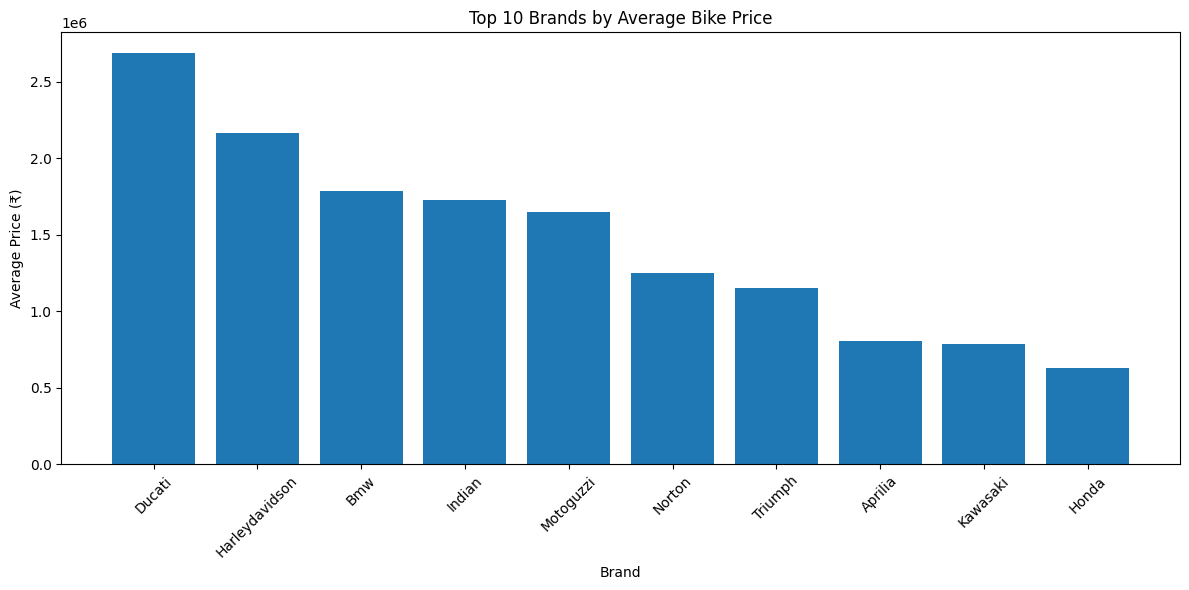

In [18]:
# Step 16: Average Price by Brand

brand_avg_price = (
    df_cleaned.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

brand_avg_price["Price"] = brand_avg_price["Price"].round(2)

print("Top 10 Brands by Average Bike Price:")
display(brand_avg_price.head(10))

print("\n10 Most Affordable Brands:")
display(brand_avg_price.tail(10).sort_values("Price"))

# Bar Chart
import matplotlib.pyplot as plt

top10 = brand_avg_price.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Brand"], top10["Price"])
plt.title("Top 10 Brands by Average Bike Price")
plt.xlabel("Brand")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Brands by Average Mileage:


,Brand,Mileage_kmpl
0,Hero,52.02
1,Tvs,47.61
2,Yamaha,47.53
3,Bajaj,46.61
4,Honda,44.78
5,Vlf,42.00
6,Suzuki,41.00
7,Vespa,40.17
8,Keeway,39.17
9,Aprilia,33.92


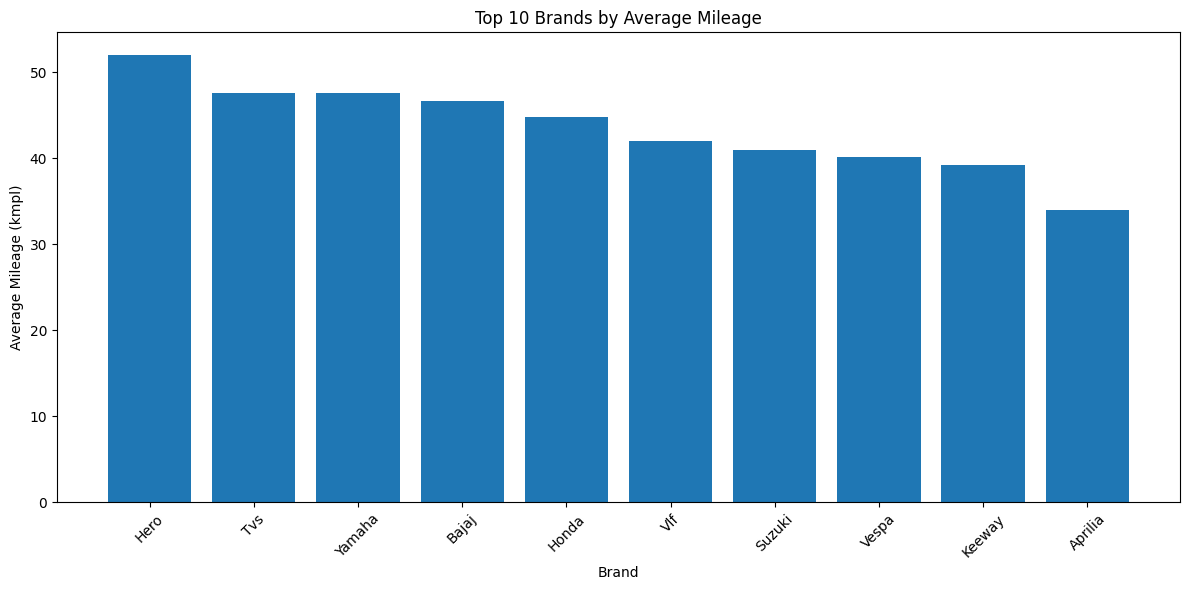

In [19]:
# Step 17: Brand-wise Average Mileage

brand_avg_mileage = (
    df_cleaned.dropna(subset=["Mileage_kmpl"])
    .groupby("Brand")["Mileage_kmpl"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

brand_avg_mileage["Mileage_kmpl"] = (
    brand_avg_mileage["Mileage_kmpl"].round(2)
)

print("Top 10 Brands by Average Mileage:")
display(brand_avg_mileage.head(10))

# Bar Chart
import matplotlib.pyplot as plt

top10_mileage = brand_avg_mileage.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    top10_mileage["Brand"],
    top10_mileage["Mileage_kmpl"]
)
plt.title("Top 10 Brands by Average Mileage")
plt.xlabel("Brand")
plt.ylabel("Average Mileage (kmpl)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Highest-Rated Bikes:


,Bike_Name,Brand,User_Rating,Price
0,Harley-Davidson Street Glide,Harleydavidson,5.0,4250000.0
1,BMW K 1600,Bmw,5.0,3800000.0
2,Aprilia RSV4 1100 Factory,Aprilia,5.0,3340763.0
3,Ducati Streetfighter V4,Ducati,5.0,2925963.0
4,BMW R 1300 GS,Bmw,5.0,2349945.0
5,Indian Chief Bobber Dark Horse,Indian,5.0,2286943.0
6,KTM 1290 Super Adventure S,Ktm,5.0,2273900.0
7,BMW S 1000 R,Bmw,5.0,2225000.0
8,Triumph Speed Triple 1200 RS,Triumph,5.0,2175900.0
9,Kawasaki Ninja ZX-10R,Kawasaki,5.0,2079000.0


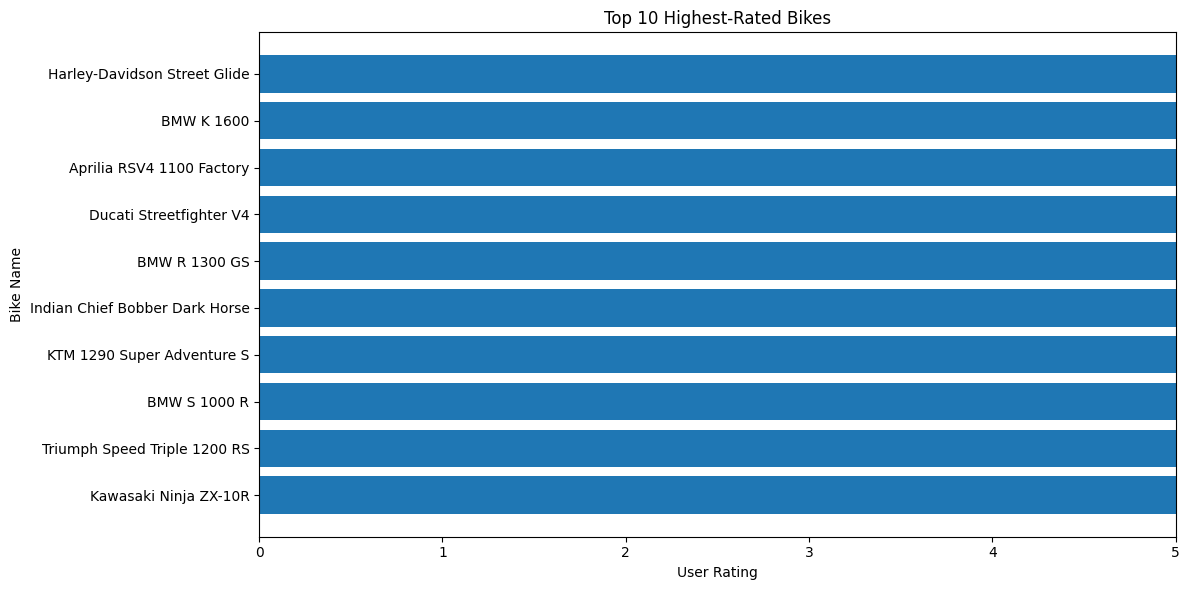

In [20]:
# Step 18: Highest-Rated Bikes

top_rated_bikes = (
    df_cleaned.dropna(subset=["User_Rating"])
    .sort_values(
        by=["User_Rating", "Price"],
        ascending=[False, False]
    )
    [["Bike_Name", "Brand", "User_Rating", "Price"]]
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 Highest-Rated Bikes:")
display(top_rated_bikes)

# Bar Chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(
    top_rated_bikes["Bike_Name"],
    top_rated_bikes["User_Rating"]
)
plt.title("Top 10 Highest-Rated Bikes")
plt.xlabel("User Rating")
plt.ylabel("Bike Name")
plt.xlim(0, 5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

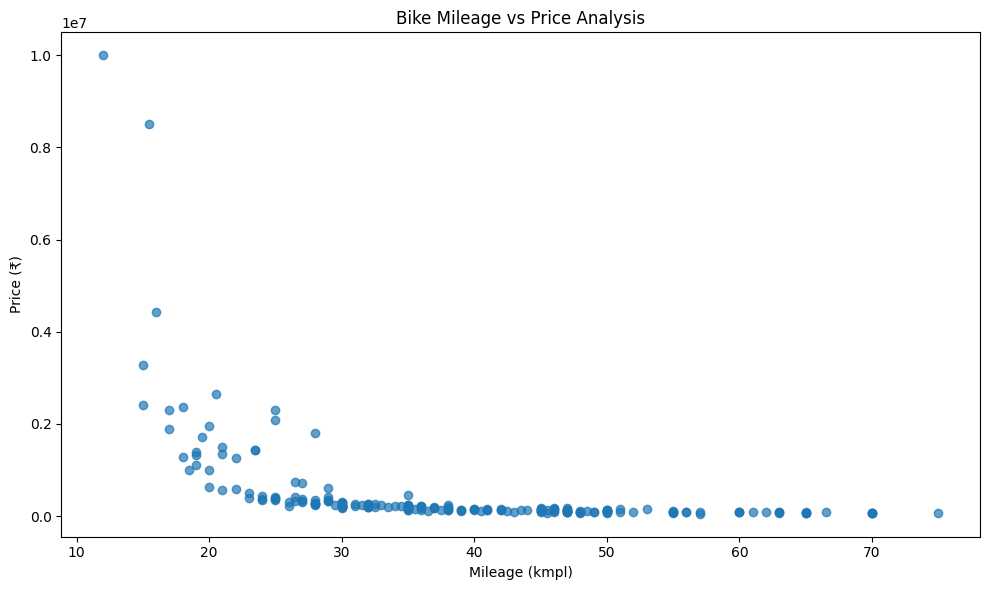

Number of Bikes Analyzed: 208
Mileage vs Price Correlation: -0.474


In [21]:
# Step 19: Mileage vs Price Analysis

import matplotlib.pyplot as plt

mileage_price = df_cleaned.dropna(
    subset=["Mileage_kmpl", "Price"]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    mileage_price["Mileage_kmpl"],
    mileage_price["Price"],
    alpha=0.7
)

plt.title("Bike Mileage vs Price Analysis")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Price (₹)")
plt.tight_layout()
plt.show()

# Correlation
correlation = mileage_price[
    ["Mileage_kmpl", "Price"]
].corr().iloc[0, 1]

print("Number of Bikes Analyzed:", len(mileage_price))
print("Mileage vs Price Correlation:", round(correlation, 3))

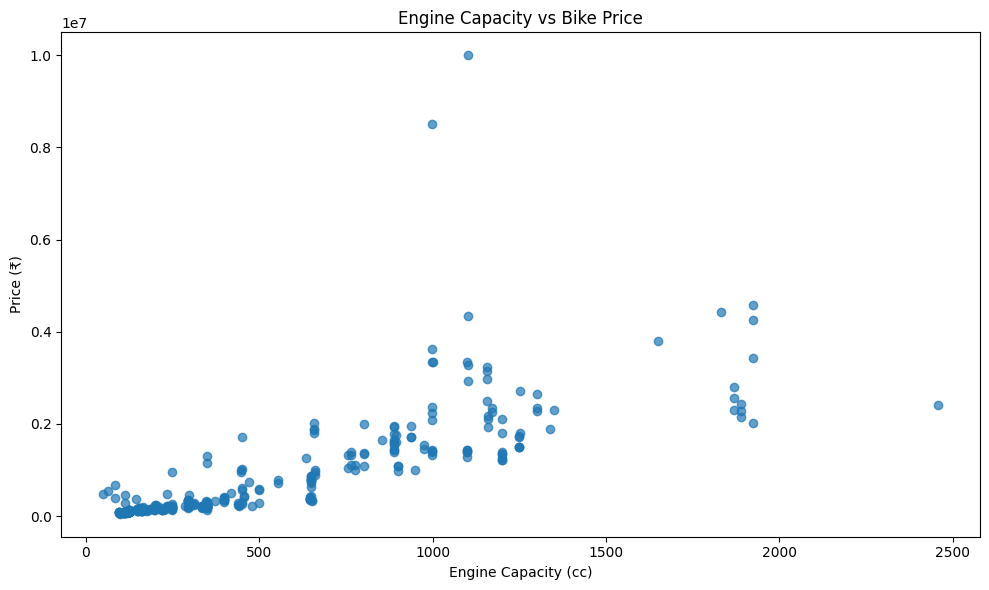

Number of Bikes Analyzed: 339
Engine Capacity vs Price Correlation: 0.764


In [22]:
# Step 20: Engine Capacity vs Price

import matplotlib.pyplot as plt

engine_price = df_cleaned.dropna(
    subset=["Engine_Capacity_cc", "Price"]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    engine_price["Engine_Capacity_cc"],
    engine_price["Price"],
    alpha=0.7
)

plt.title("Engine Capacity vs Bike Price")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Price (₹)")
plt.tight_layout()
plt.show()

correlation = engine_price[
    ["Engine_Capacity_cc", "Price"]
].corr().iloc[0, 1]

print("Number of Bikes Analyzed:", len(engine_price))
print("Engine Capacity vs Price Correlation:", round(correlation, 3))

Top 10 Most Expensive Bikes:


,Bike_Name,Brand,Price,Engine_Capacity_cc
0,Ducati Panigale V4 Lamborghini,Ducati,10000000.0,1103.0
1,Ducati Panigale V4 R,Ducati,8499000.0,998.0
2,Harley-Davidson Road Glide,Harleydavidson,4575000.0,1923.0
3,Honda Goldwing,Honda,4430000.0,1833.0
4,Ducati Multistrada V4 RS,Ducati,4346700.0,1103.0
5,Harley-Davidson Street Glide,Harleydavidson,4250000.0,1923.0
6,"Honda CBR 1 model available ₹ 41,64,930 Onward...",Honda,4164930.0,NaN
7,BMW K 1600,Bmw,3800000.0,1649.0
8,Kawasaki Ninja H2 SX SE,Kawasaki,3627783.0,998.0
9,Harley-Davidson Breakout,Harleydavidson,3436000.0,1923.0


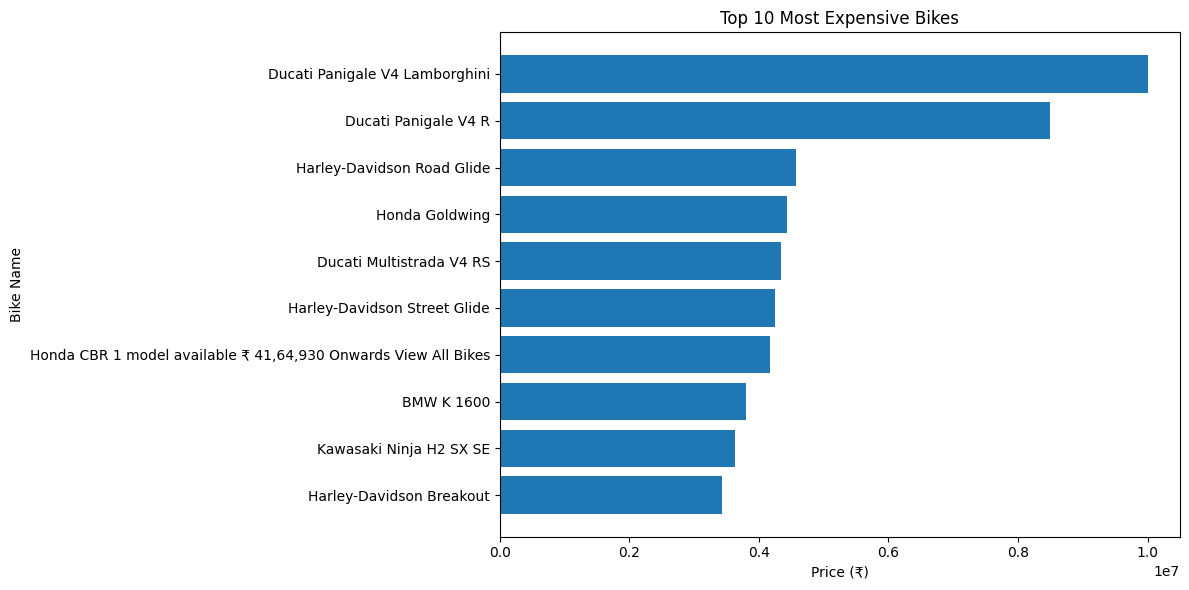

In [23]:
# Step 21: Top 10 Most Expensive Bikes

top_expensive_bikes = (
    df_cleaned.sort_values(
        by="Price",
        ascending=False
    )
    [["Bike_Name", "Brand", "Price", "Engine_Capacity_cc"]]
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 Most Expensive Bikes:")
display(top_expensive_bikes)

# Bar Chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_expensive_bikes["Bike_Name"],
    top_expensive_bikes["Price"]
)

plt.title("Top 10 Most Expensive Bikes")
plt.xlabel("Price (₹)")
plt.ylabel("Bike Name")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [24]:
# Step 22: Top 10 Most Affordable Bikes

affordable_bikes = (
    df_cleaned.sort_values("Price", ascending=True)
    [["Bike_Name", "Brand", "Price", "Engine_Capacity_cc"]]
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 Most Affordable Bikes:")
display(affordable_bikes)

Top 10 Most Affordable Bikes:


,Bike_Name,Brand,Price,Engine_Capacity_cc
0,TVS XL 100 Heavy Duty,Tvs,47929.0,99.7
1,Lectrix SX25,Lectrix,54999.0,NaN
2,Evolet Pony,Evolet,55799.0,NaN
3,Hero HF Deluxe,Hero,58719.0,97.2
4,TVS XL EV,Tvs,60000.0,NaN
5,TVS XL 100 Comfort,Tvs,60380.0,99.7
6,Joy e-bike Gen Nxt,Joyebike,60827.0,NaN
7,Joy e-bike Wolf,Joyebike,61877.0,NaN
8,Okinawa R30,Okinawa,61998.0,NaN
9,TVS Sport,Tvs,65721.0,109.7


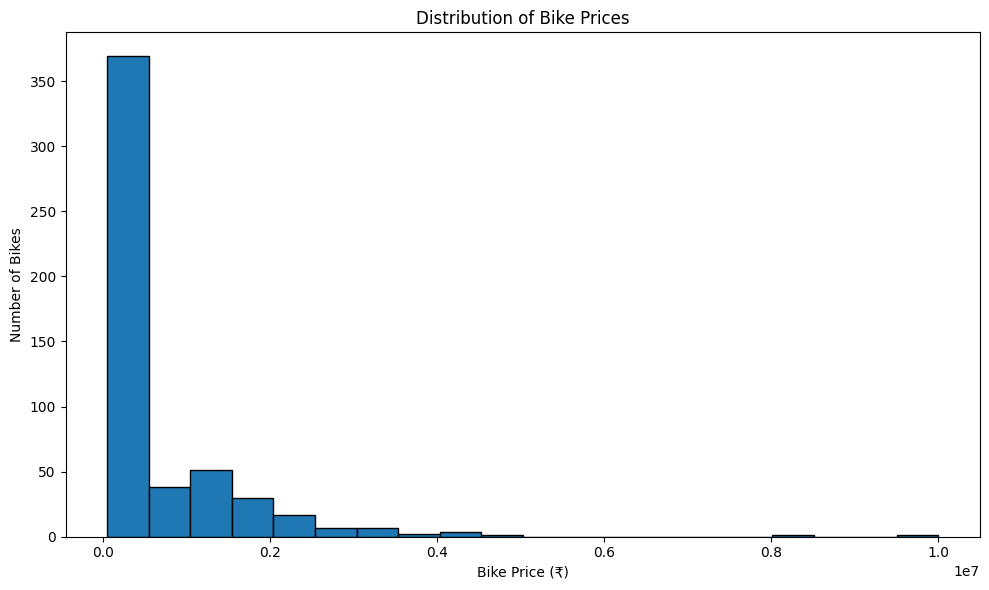

In [25]:
# Step 23: Price Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df_cleaned["Price"], bins=20, edgecolor="black")

plt.title("Distribution of Bike Prices")
plt.xlabel("Bike Price (₹)")
plt.ylabel("Number of Bikes")

plt.tight_layout()
plt.show()

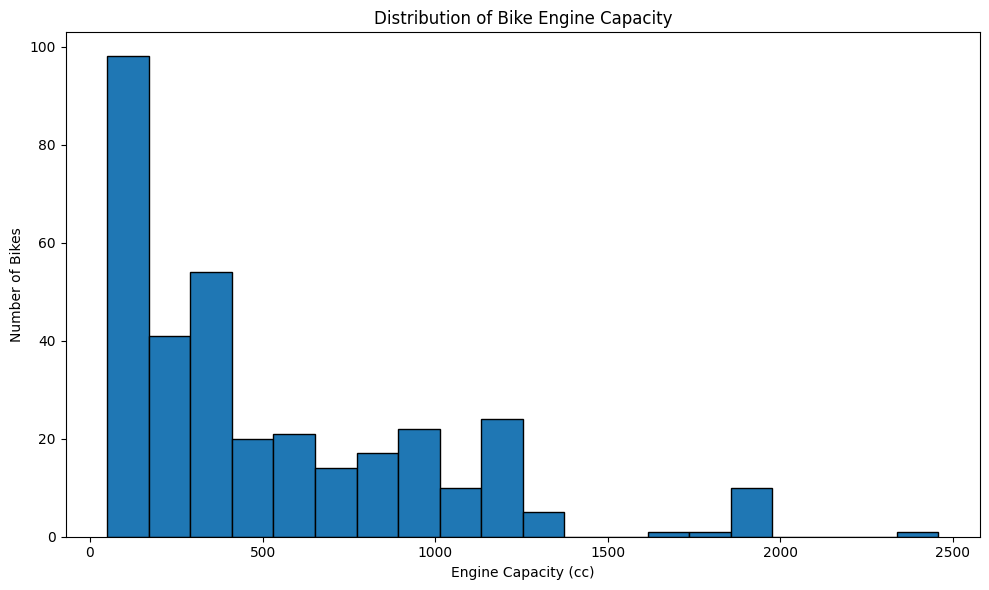

Bikes with engine capacity: 339


In [26]:
# Step 24: Engine Capacity Distribution

engine_data = df_cleaned["Engine_Capacity_cc"].dropna()

plt.figure(figsize=(10, 6))

plt.hist(engine_data, bins=20, edgecolor="black")

plt.title("Distribution of Bike Engine Capacity")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Number of Bikes")

plt.tight_layout()
plt.show()

print("Bikes with engine capacity:", len(engine_data))

Top 10 Brands by Number of Bikes:


,Brand,count
0,Honda,41
1,Kawasaki,40
2,Triumph,36
3,Ktm,33
4,Hero,31
5,Tvs,29
6,Bajaj,29
7,Yamaha,26
8,Ducati,25
9,Royalenfield,24


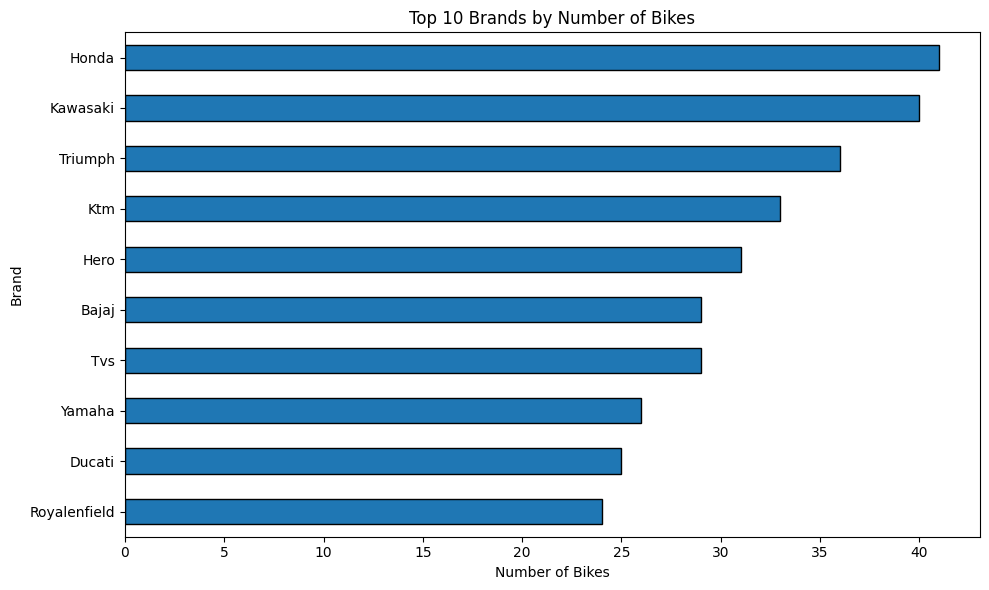

In [27]:
# Step 25: Brand-wise Bike Count

import matplotlib.pyplot as plt

brand_counts = (
    df_cleaned["Brand"]
    .value_counts()
    .head(10)
)

print("Top 10 Brands by Number of Bikes:")
display(brand_counts.reset_index())

plt.figure(figsize=(10, 6))

brand_counts.sort_values().plot(kind="barh", edgecolor="black")

plt.title("Top 10 Brands by Number of Bikes")
plt.xlabel("Number of Bikes")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

In [28]:
# Step 26: Business Insights

print("BIKE MARKET ANALYSIS - KEY INSIGHTS")
print("-" * 40)

print("Total Bikes:", len(df_cleaned))
print("Total Brands:", df_cleaned["Brand"].nunique())

print(
    "Average Bike Price: ₹",
    round(df_cleaned["Price"].mean(), 2)
)

print(
    "Average Mileage (km/l):",
    round(df_cleaned["Mileage_kmpl"].mean(), 2)
)

highest_bike = df_cleaned.loc[df_cleaned["Price"].idxmax()]
print("\nMost Expensive Bike:", highest_bike["Bike_Name"])
print("Brand:", highest_bike["Brand"])
print("Price: ₹", highest_bike["Price"])

lowest_bike = df_cleaned.loc[df_cleaned["Price"].idxmin()]
print("\nMost Affordable Bike:", lowest_bike["Bike_Name"])
print("Brand:", lowest_bike["Brand"])
print("Price: ₹", lowest_bike["Price"])

print(
    "\nBikes with Mileage Data:",
    df_cleaned["Mileage_kmpl"].notna().sum()
)

print(
    "Bikes with Engine Capacity Data:",
    df_cleaned["Engine_Capacity_cc"].notna().sum()
)

BIKE MARKET ANALYSIS - KEY INSIGHTS
----------------------------------------
Total Bikes: 528
Total Brands: 56
Average Bike Price: ₹ 662212.87
Average Mileage (km/l): 38.27

Most Expensive Bike: Ducati Panigale V4 Lamborghini
Brand: Ducati
Price: ₹ 10000000.0

Most Affordable Bike: TVS XL 100 Heavy Duty
Brand: Tvs
Price: ₹ 47929.0

Bikes with Mileage Data: 208
Bikes with Engine Capacity Data: 339


In [29]:
# Step 27: Business Recommendations

print("BIKE MARKET ANALYSIS - BUSINESS RECOMMENDATIONS")
print("=" * 50)

print("\n1. Affordable Bikes:")
print("TVS, Hero and other budget-friendly brands can target")
print("customers looking for low-cost bikes.")

print("\n2. Premium Bikes:")
print("Brands like Ducati, BMW and Harley-Davidson can focus")
print("on premium customers looking for high-performance bikes.")

print("\n3. Mileage:")
print("Hero, TVS, Yamaha and Bajaj show strong average mileage")
print("among the brands with available mileage data.")

print("\n4. Engine Capacity and Price:")
print("The analysis found a strong positive relationship between")
print("engine capacity and price in the available data.")

print("\n5. Customer Ratings:")
print("Highly rated bikes can be highlighted in marketing,")
print("but the number of ratings should also be checked.")

print("\n6. Data Quality:")
print("Mileage and engine capacity are missing for many bikes.")
print("Collecting complete specifications can improve analysis.")

print("\n7. Market Strategy:")
print("Offer different bike options for budget, mid-range,")
print("premium and luxury customer segments.")

BIKE MARKET ANALYSIS - BUSINESS RECOMMENDATIONS

1. Affordable Bikes:
TVS, Hero and other budget-friendly brands can target
customers looking for low-cost bikes.

2. Premium Bikes:
Brands like Ducati, BMW and Harley-Davidson can focus
on premium customers looking for high-performance bikes.

3. Mileage:
Hero, TVS, Yamaha and Bajaj show strong average mileage
among the brands with available mileage data.

4. Engine Capacity and Price:
The analysis found a strong positive relationship between
engine capacity and price in the available data.

5. Customer Ratings:
Highly rated bikes can be highlighted in marketing,
but the number of ratings should also be checked.

6. Data Quality:
Mileage and engine capacity are missing for many bikes.

7. Market Strategy:
Offer different bike options for budget, mid-range,
premium and luxury customer segments.


In [30]:
# Step 28: Save Final Cleaned Dataset

df_cleaned.to_csv("bike_market_cleaned.csv", index=False)

from google.colab import files
files.download("bike_market_cleaned.csv")

print("Final cleaned dataset saved successfully!")
print("Total Records:", len(df_cleaned))
print("Total Columns:", len(df_cleaned.columns))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final cleaned dataset saved successfully!
Total Records: 528
Total Columns: 19
